MENTAL HEALTH SCORE PREDICOR

Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

Load dataset

In [2]:
df=pd.read_csv("studentData.csv")

In [3]:
df.head()

,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score
0,21,Male,Other,Undergraduate,Facebook,Networking,4.0,134,4.5,2.2,6.7,Medium,6.8
1,23,Female,Other,Graduate,LinkedIn,Education,1.6,73,7.0,2.4,8.6,Low,7.6
2,22,Male,Canada,Undergraduate,Instagram,Entertainment,4.6,166,4.0,1.8,6.7,Medium,7.0
3,18,Male,Other,High School,Snapchat,Entertainment,7.0,220,1.0,1.7,5.4,Very High,5.3
4,24,Female,Other,Graduate,Facebook,Networking,7.5,237,1.0,1.1,5.0,Very High,4.4


In [4]:
#looking for number of rows and columns
df.shape

(5000, 13)

In [5]:
df.isnull().sum()

,0
Age,0
Gender,0
Country,0
Academic_Level,0
Most_Used_Platform,0
Purpose_Of_Use,0
Avg_Daily_Usage_Hours,0
Daily_Unlocks,0
Study_Hours,0
Physical_Activity_Hours,0


In [6]:
df.duplicated().sum()

np.int64(2)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      5000 non-null   int64  
 1   Gender                   5000 non-null   object 
 2   Country                  5000 non-null   object 
 3   Academic_Level           5000 non-null   object 
 4   Most_Used_Platform       5000 non-null   object 
 5   Purpose_Of_Use           5000 non-null   object 
 6   Avg_Daily_Usage_Hours    5000 non-null   float64
 7   Daily_Unlocks            5000 non-null   int64  
 8   Study_Hours              5000 non-null   float64
 9   Physical_Activity_Hours  5000 non-null   float64
 10  Sleep_Hours_Per_Night    5000 non-null   float64
 11  Stress_Level             5000 non-null   object 
 12  Mental_Health_Score      5000 non-null   float64
dtypes: float64(5), int64(2), object(6)
memory usage: 507.9+ KB


In [8]:
df.columns

Index(['Age', 'Gender', 'Country', 'Academic_Level', 'Most_Used_Platform',
       'Purpose_Of_Use', 'Avg_Daily_Usage_Hours', 'Daily_Unlocks',
       'Study_Hours', 'Physical_Activity_Hours', 'Sleep_Hours_Per_Night',
       'Stress_Level', 'Mental_Health_Score'],
      dtype='object')

In [9]:
df.describe()

,Age,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
count,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,20.82180,5.078460,171.452600,3.008420,1.751000,6.634580,6.230980
std,1.73662,1.653913,42.858254,1.637018,0.668398,1.221391,1.278701
min,18.00000,1.000000,62.000000,0.300000,-0.400000,3.600000,3.600000
25%,19.00000,3.800000,140.000000,1.500000,1.300000,5.600000,5.100000
50%,21.00000,5.000000,171.000000,2.800000,1.700000,6.600000,6.100000
75%,22.00000,6.300000,204.000000,4.200000,2.200000,7.500000,7.100000
max,24.00000,8.800000,273.000000,8.300000,4.100000,9.900000,9.400000


EDA

<Axes: xlabel='Mental_Health_Score', ylabel='Count'>

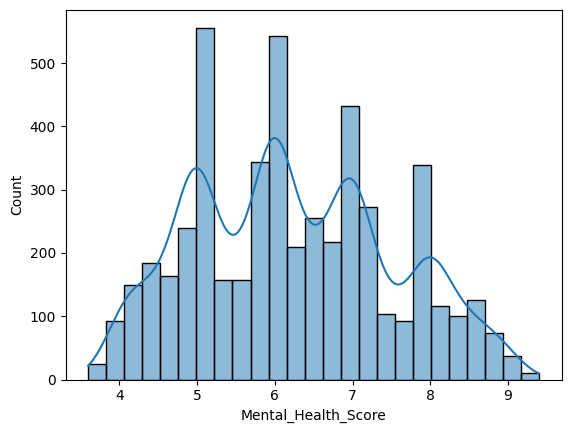

In [10]:
# distribution of target
sns.histplot(df['Mental_Health_Score'],kde=True)

<Axes: >

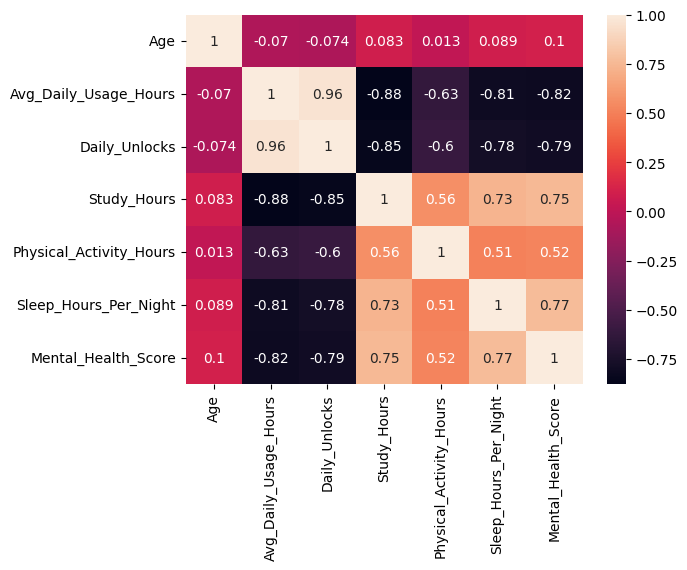

In [11]:
#correclationheap map:numerical feature
sns.heatmap(df.corr(numeric_only=True),annot=True)

In [12]:
df['Stress_Level'].unique()

array(['Medium', 'Low', 'Very High', 'High'], dtype=object)

<Axes: xlabel='Stress_Level', ylabel='Mental_Health_Score'>

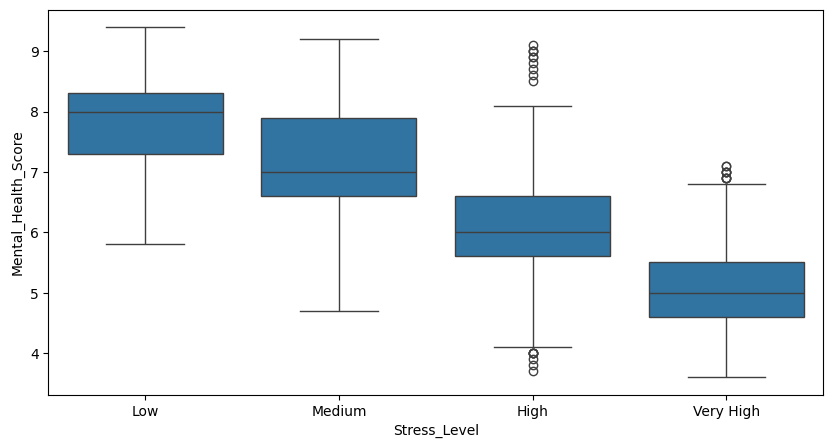

In [13]:
# stress level vs mental score
plt.figure(figsize=(10,5))
order=['Low','Medium','High','Very High']
sns.boxplot(x='Stress_Level',y='Mental_Health_Score',data=df,order=order)

<Axes: xlabel='Avg_Daily_Usage_Hours', ylabel='Mental_Health_Score'>

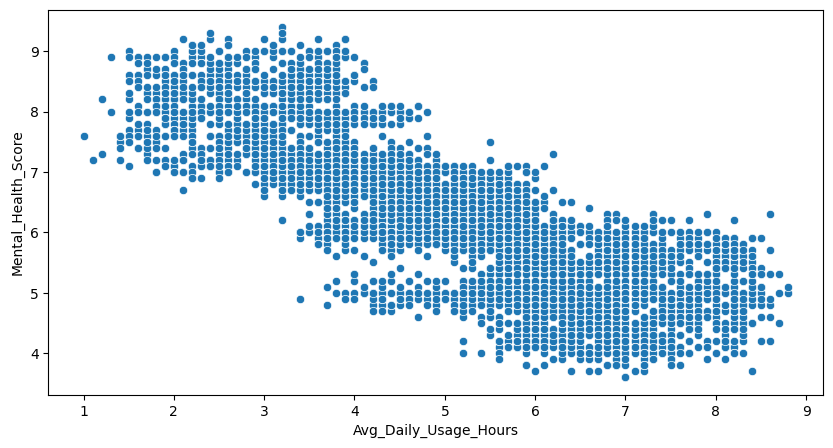

In [14]:
# daily_uses_hours vs mental_score
plt.figure(figsize=(10,5))
# order=['Low','Medium','High','Very High']
sns.scatterplot(x='Avg_Daily_Usage_Hours',y='Mental_Health_Score',data=df)

<Axes: xlabel='Sleep_Hours_Per_Night', ylabel='Mental_Health_Score'>

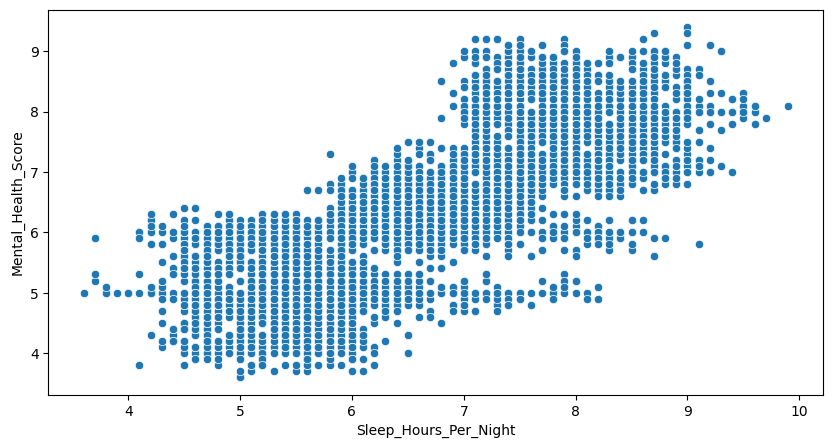

In [15]:
#Sleep_Hours_Per_Night vs Mental_Health_Score
plt.figure(figsize=(10,5))
sns.scatterplot(x='Sleep_Hours_Per_Night',y='Mental_Health_Score',data=df)

In [16]:
platform_count=df['Most_Used_Platform'].value_counts()
platform_count

,count
Most_Used_Platform,
Instagram,1130
TikTok,918
Facebook,719
LinkedIn,523
YouTube,491
Twitter,462
Snapchat,420
WhatsApp,175
LINE,50


<Axes: xlabel='count', ylabel='Most_Used_Platform'>

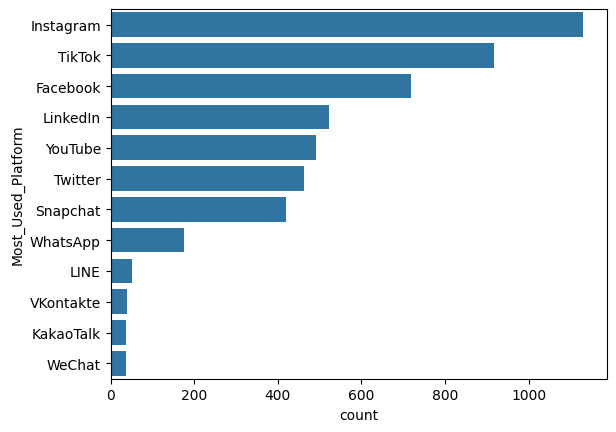

In [17]:
sns.countplot(y=df['Most_Used_Platform'],order=df['Most_Used_Platform'].value_counts().index)

Checking Outliers


In [18]:
num_features=df.select_dtypes(include=np.number)
Q1=num_features.quantile(0.25)
Q3=num_features.quantile(0.75)
IQR=Q3-Q1

lower_bound=Q1-1.5*IQR
upper_bound=Q3+1.5*IQR

outliers=(num_features<lower_bound) |(num_features>upper_bound)
print(outliers.sum())

Age                         0
Avg_Daily_Usage_Hours       0
Daily_Unlocks               0
Study_Hours                 2
Physical_Activity_Hours    22
Sleep_Hours_Per_Night       0
Mental_Health_Score         0
dtype: int64


Data cleaning

In [19]:
# to drop duplicates
df=df.drop_duplicates()

#covering nagative or unrealstic value to realistic value by using clip
df['Physical_Activity_Hours']=df['Physical_Activity_Hours'].clip(lower=0)


In [20]:
df.describe()

,Age,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
count,4998.000000,4998.000000,4998.000000,4998.000000,4998.000000,4998.000000,4998.000000
mean,20.822129,5.078491,171.455582,3.008403,1.751160,6.634654,6.231152
std,1.736774,1.654097,42.859829,1.636831,0.667282,1.221561,1.278476
min,18.000000,1.000000,62.000000,0.300000,0.000000,3.600000,3.600000
25%,19.000000,3.800000,140.000000,1.500000,1.300000,5.600000,5.100000
50%,21.000000,5.000000,171.000000,2.800000,1.700000,6.600000,6.100000
75%,22.000000,6.300000,204.000000,4.200000,2.200000,7.500000,7.100000
max,24.000000,8.800000,273.000000,8.300000,4.100000,9.900000,9.400000


SKENESS: meassure your data is belong  to centrilized or right skew or left skew

In [21]:
numerical_cols=df.select_dtypes(include="number")
numerical_cols.skew()
#near to 0->centralized
#negative->left skewed
#positive(greater than 0)->Right skewed


,0
Age,0.155008
Avg_Daily_Usage_Hours,0.005575
Daily_Unlocks,0.002309
Study_Hours,0.436125
Physical_Activity_Hours,0.053288
Sleep_Hours_Per_Night,0.123919
Mental_Health_Score,0.207086


Feature Engineering

In [22]:
top_countries=df['Country'].value_counts().index[:10].to_list()

In [23]:
def group_countries(country):
  if country in top_countries:
    return country
  else:
    return 'Other'

In [24]:
df['Grouped_country']=df['Country'].apply(group_countries)

In [25]:
df['Grouped_country'].value_counts()

,count
Grouped_country,
Other,3231
India,389
USA,354
Canada,230
Australia,198
UK,185
Germany,136
Mexico,94
Turkey,94


Train_test split

In [26]:
from sklearn.model_selection import train_test_split
skewes_col=['Study_Hours']
#skew colum go though the logtransform and  standared
other_numeric_col=['Age','Avg_Daily_Usage_Hours' ,'Daily_Unlocks','Physical_Activity_Hours','Sleep_Hours_Per_Night','Mental_Health_Score']

ordinal_col=['Stress_Level']
normal_col=['Gender', 'Academic_Level', 'Most_Used_Platform',
       'Purpose_Of_Use', 'Grouped_country']

feature_col=skewes_col+other_numeric_col+ordinal_col+normal_col
X=df[feature_col]
y=df['Mental_Health_Score']
X_train, X_test, y_train, y_test = train_test_split(
     X, y, test_size=0.30, random_state=42)



In [27]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler,OneHotEncoder,OrdinalEncoder
from sklearn.preprocessing import  FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

#1. skewed feature
skew_pipeline=Pipeline(steps=[('log_transform',FunctionTransformer(np.log1p)),
                              ('scale',StandardScaler())
])
#2.plain_numeric feature
plain_numeric_pipeline=Pipeline(steps=[('scale',StandardScaler())])

#3.ordinal  freature
ordinal_pipeline=Pipeline(steps=[
  ('ordinal_encoder',OrdinalEncoder(categories=[['Low','Medium','High','Very High']]))
  ])

#4. normal feature categorical
normal_pipeline=Pipeline(steps=[('one_hot_encoder',OneHotEncoder(handle_unknown='ignore'))])


#columnTransformers
preprocessor=ColumnTransformer(transformers=[
    ('skew_pipeline',skew_pipeline,skewes_col),
    ('plain_numeric_pipeline',plain_numeric_pipeline,other_numeric_col),
    ('ordinal_pipeline',ordinal_pipeline,ordinal_col),
    ('normal_pipeline',normal_pipeline,normal_col)
])







In [28]:
# linear regression model pipeline

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error,r2_score,mean_absolute_error
lr_pipeline=Pipeline(steps=[
    ('preprocessor',preprocessor),
    ('regressor',LinearRegression())
])
lr_pipeline.fit(X_train,y_train)
lr_preds=lr_pipeline.predict(X_test)
lr_preds_train=lr_pipeline.predict(X_train)



lr_r2_testing=r2_score(y_test,lr_preds)
lr_r2_traning=r2_score(y_train,lr_preds_train)

lr_mse=mean_squared_error(y_test,lr_preds)
lr_mae=mean_absolute_error(y_test,lr_preds)
print(f"accuracy of testing {lr_r2_testing}")
print(f"accuracy of traning {lr_r2_traning}")
print(f"mse {lr_mse}")
print(f"mae {lr_mae}")



accuracy of testing 1.0
accuracy of traning 1.0
mse 3.37593024389332e-30
mae 1.4196051741540335e-15


In [29]:
#random forest model
from sklearn.ensemble import RandomForestRegressor

rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('random forest', RandomForestRegressor(random_state=42))
])

rf_pipeline.fit(X_train, y_train)
rf_preds          = rf_pipeline.predict(X_test)
rf_preds_training = rf_pipeline.predict(X_train)

rf_r2_testing  = r2_score(y_test, rf_preds)
rf_r2_training = r2_score(y_train, rf_preds_training)
rf_mae         = mean_absolute_error(y_test, rf_preds)

print(f"Accuracy of Training {rf_r2_training}")
print(f"Accuracy of Testing {rf_r2_testing}")
print(f"MAE : {rf_mae}")


Accuracy of Training 0.9999990409282065
Accuracy of Testing 0.9999984547737636
MAE : 0.00012333333333923473


In [30]:
from sklearn.model_selection import RandomizedSearchCV

param_grid = {
    'random forest__n_estimators'       : [100,200,300],
    'random forest__max_depth'         : [5,10,15],
    'random forest__min_samples_split' : [2,5,10],
    'random forest__min_samples_leaf'  : [1,2,4]
}

random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_grid,
    n_iter = 15,
    cv = 5,
    scoring='r2',
    random_state=42,
    n_jobs =-1 #processor free
)

random_search.fit(X_train, y_train)

RandomizedSearchCV(cv=5,
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('skew_pipeline',
                                                                               Pipeline(steps=[('log_transform',
                                                                                                FunctionTransformer(func=<ufunc 'log1p'>)),
                                                                                               ('scale',
                                                                                                StandardScaler())]),
                                                                               ['Study_Hours']),
                                                                              ('plain_numeric_pipeline',
                                                                               Pipeline(steps=[('scale',
                                                                                                StandardScaler())]),
                                                                               ['Age',
                                                                                'Avg_Daily_Usage_Hours',
                                                                                'Daily_Unloc...
                                                                                'Most_Used_Platform',
                                                                                'Purpose_Of_Use',
                                                                                'Grouped_country'])])),
                                             ('random forest',
                                              RandomForestRegressor(random_state=42))]),
                   n_iter=15, n_jobs=-1,
                   param_distributions={'random forest__max_depth': [5, 10, 15],
                                        'random forest__min_samples_leaf': [1,
                                                                            2,
                                                                            4],
                                        'random forest__min_samples_split': [2,
                                                                             5,
                                                                             10],
                                        'random forest__n_estimators': [100,
                                                                        200,
                                                                        300]},
                   random_state=42, scoring='r2')

In [31]:

random_search.best_params_

{'random forest__n_estimators': 200,
 'random forest__min_samples_split': 2,
 'random forest__min_samples_leaf': 1,
 'random forest__max_depth': 10}

In [32]:
rf_best_pipeline = random_search.best_estimator_
rf_best_preds    = rf_best_pipeline.predict(X_test)
print(f"R2 Score for random forest after hyperparameter tuning {r2_score(y_test, rf_best_preds)}")
print(f"MAE Score for random forest after hyperparameter tuning {mean_absolute_error(y_test, rf_best_preds)}")


R2 Score for random forest after hyperparameter tuning 0.9999985601991105
MAE Score for random forest after hyperparameter tuning 0.00011833333334455531


In [33]:

from sklearn.metrics import mean_squared_error

# Calculate RMSE for Linear Regression
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_preds))

# Calculate RMSE for default Random Forest
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_preds))

# Calculate RMSE for tuned Random Forest
rf_tuned_preds          = random_search.best_estimator_.predict(X_test)
rf_tuned_rmse           = np.sqrt(mean_squared_error(y_test, rf_tuned_preds))
rf_tuned_training_preds = random_search.best_estimator_.predict(X_train)
r2_tuned_training       = r2_score(y_train, rf_tuned_training_preds)
rf_tuned_mae            = mean_absolute_error(y_test, rf_tuned_preds)
rf_tuned_r2             = r2_score(y_test, rf_tuned_preds)


# Create a DataFrame to consolidate results
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest (default)', 'Random Forest (tuned)'],
    'R2': [lr_r2_testing, rf_r2_testing, rf_tuned_r2],
    'Training R2': [lr_r2_traning, rf_r2_training, r2_tuned_training],
    'MAE': [lr_mae, rf_mae, rf_tuned_mae],
    'RMSE': [lr_rmse, rf_rmse, rf_tuned_rmse]
})

print(results)

                     Model        R2  Training R2           MAE          RMSE
0        Linear Regression  1.000000     1.000000  1.419605e-15  1.837370e-15
1  Random Forest (default)  0.999998     0.999999  1.233333e-04  1.647422e-03
2    Random Forest (tuned)  0.999999     0.999999  1.183333e-04  1.590231e-03


In [34]:
import joblib
joblib.dump(rf_pipeline, 'Mental_Health_Model.pkl')


['Mental_Health_Model.pkl']